# MIDV-2020 dataset investigation

This notebook turns the MIDV-2020 files into evidence for the project's experimental contract. It is intentionally **exploratory and didactic**: each section explains the question, the reason it matters, the measurement, and the limits of what we can conclude.

The notebook does not rename, move, modify, or preprocess dataset files. It only reads them.

## Questions answered here

1. How are templates, photographs, identities, and annotations related?
2. Which raw fields are annotated for each card type, and how consistently?
3. Does “missing” mean absent annotation, missing value, or empty value?
4. What are the observed image formats, modes, dimensions, and array shapes?
5. How much of each photograph is occupied by the annotated document polygon?
6. How are photo IDs related to device and capture condition?
7. What is the correct leakage-safe evaluation unit?
8. What evidence should guide selection of the first card type?
9. Which dataset anomalies and limitations must be recorded?

The statistical work requested for **Investigations 10–17** begins after a compact reconstruction of the foundational inspection.

## How to use this notebook

Run cells from top to bottom. Whenever a table appears, practice reading it before continuing:

- What is the **unit of one row**?
- Is a count measuring regions, samples, identities, or document types?
- Is a conclusion directly observed, or merely inferred?
- Would the result change if we used photographs instead of templates?

The final section is a decision worksheet. The notebook prepares evidence, but it deliberately does not choose the canonical schema or first document type for us.

## 0 — Setup and reproducibility

`Path` keeps paths portable. The repository-root detection allows the notebook to work when Jupyter starts either in the repository root or inside `notebooks/`.

Names are explicit:

- `dataset_root` means the extracted `data/raw` directory.
- `document_type` means a layout such as `alb_id`.
- `sample_id` means the filename stem such as `00`.
- `identity_key` means the stable pair `document_type/sample_id`.
- `source` means `templates` or `photo`.

In [1]:
from collections import Counter
from hashlib import sha256
from pathlib import Path
import json
import os
import tarfile

current_directory = Path.cwd().resolve()
if (current_directory / "PROJECT.md").exists():
    repository_root = current_directory
elif (current_directory.parent / "PROJECT.md").exists():
    repository_root = current_directory.parent
else:
    raise FileNotFoundError(
        "Start Jupyter from the repository root or the notebooks directory."
    )

# Matplotlib needs a writable cache. /tmp avoids adding generated cache files to Git.
os.environ.setdefault("MPLCONFIGDIR", "/tmp/kyc-router-matplotlib")

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd
from PIL import Image

data_directory = repository_root / "data"
dataset_root = data_directory / "raw"
template_root = dataset_root / "templates"
photo_root = dataset_root / "photo"

card_document_types = ("alb_id", "esp_id", "est_id", "fin_id", "svk_id")
all_document_types = tuple(
    sorted(path.stem for path in (template_root / "annotations").glob("*.json"))
)

# These are annotated visual regions, not textual output fields.
non_text_region_names = frozenset({"face", "photo", "signature", "doc_quad"})

print(f"Repository root: {repository_root}")
print(f"Dataset root:    {dataset_root}")
print(f"Document types:  {all_document_types}")

Repository root: /home/raspiestchip/kyc-router
Dataset root:    /home/raspiestchip/kyc-router/data/raw
Document types:  ('alb_id', 'aze_passport', 'esp_id', 'est_id', 'fin_id', 'grc_passport', 'lva_passport', 'rus_internalpassport', 'srb_passport', 'svk_id')


### Confirm the expected files exist

Failing early gives a clearer error than discovering a missing directory halfway through the analysis.

In [2]:
required_paths = [
    template_root / "images",
    template_root / "annotations",
    photo_root / "images",
    photo_root / "annotations",
]

for required_path in required_paths:
    if not required_path.exists():
        raise FileNotFoundError(required_path)

file_inventory = pd.DataFrame(
    [
        {
            "source": source,
            "document_type": document_type,
            "image_files": len(list((dataset_root / source / "images" / document_type).glob("*"))),
            "annotation_file_exists": (
                dataset_root / source / "annotations" / f"{document_type}.json"
            ).exists(),
        }
        for source in ("templates", "photo")
        for document_type in all_document_types
    ]
)

file_inventory

,source,document_type,image_files,annotation_file_exists
0,templates,alb_id,100,True
1,templates,aze_passport,100,True
2,templates,esp_id,100,True
3,templates,est_id,100,True
4,templates,fin_id,100,True
5,templates,grc_passport,100,True
6,templates,lva_passport,100,True
7,templates,rus_internalpassport,100,True
8,templates,srb_passport,100,True
9,templates,svk_id,100,True


### Optional archive inspection

The extracted files are the main object of study. If we inspect the large TAR files, we take only the first few entries instead of materializing every member name in memory.

In [3]:
def first_archive_members(archive_path, limit=12):
    '''Return a small prefix of member names without extracting the archive.'''
    member_names = []
    with tarfile.open(archive_path) as archive:
        for index, member in enumerate(archive):
            if index == limit:
                break
            member_names.append(member.name)
    return member_names


archive_preview = {
    archive_path.name: first_archive_members(archive_path)
    for archive_path in (data_directory / "templates.tar", data_directory / "photo.tar")
    if archive_path.exists()
}
archive_preview

{'templates.tar': ['annotations',
  'annotations/alb_id.json',
  'annotations/rus_internalpassport.json',
  'annotations/est_id.json',
  'annotations/lva_passport.json',
  'annotations/grc_passport.json',
  'annotations/aze_passport.json',
  'annotations/esp_id.json',
  'annotations/fin_id.json',
  'annotations/srb_passport.json',
  'annotations/svk_id.json',
  'images'],
 'photo.tar': ['annotations',
  'annotations/alb_id.json',
  'annotations/rus_internalpassport.json',
  'annotations/est_id.json',
  'annotations/lva_passport.json',
  'annotations/grc_passport.json',
  'annotations/aze_passport.json',
  'annotations/esp_id.json',
  'annotations/fin_id.json',
  'annotations/srb_passport.json',
  'annotations/svk_id.json',
  'images']}

## 1 — A small, reusable MIDV data model

MIDV uses the VGG Image Annotator (VIA) JSON format. A record lives under `_via_img_metadata`. The dictionary key combines filename and file size, so it is an implementation detail—not a stable sample identifier. We index records by their explicit `filename` instead.

A region contains:

- `shape_attributes`: *where* the region is;
- `region_attributes`: *what* it represents, including `field_name` and sometimes `value`.

In [4]:
def annotation_path(source, document_type):
    return dataset_root / source / "annotations" / f"{document_type}.json"


def image_path(source, document_type, filename):
    return dataset_root / source / "images" / document_type / filename


def load_via_metadata(source, document_type):
    '''Load VIA metadata and return records keyed by filename.'''
    path = annotation_path(source, document_type)
    with path.open(encoding="utf-8") as annotation_file:
        via_document = json.load(annotation_file)

    raw_metadata = via_document["_via_img_metadata"]
    records_by_filename = {
        record["filename"]: record for record in raw_metadata.values()
    }

    if len(records_by_filename) != len(raw_metadata):
        raise ValueError(f"Duplicate filenames in {path}")

    return records_by_filename


def make_identity_key(document_type, filename):
    '''Identify the underlying mock document independently of its source/view.'''
    return f"{document_type}/{Path(filename).stem}"


def regions_named(record, field_name):
    '''Return every region whose field_name exactly matches field_name.'''
    return [
        region
        for region in record.get("regions", [])
        if region.get("region_attributes", {}).get("field_name") == field_name
    ]


metadata_by_source = {
    source: {
        document_type: load_via_metadata(source, document_type)
        for document_type in all_document_types
    }
    for source in ("templates", "photo")
}

### One identity, two observations

`alb_id/00` is the identity key. The template and photograph are different observations of that same printed mock document. This distinction later prevents train/test leakage.

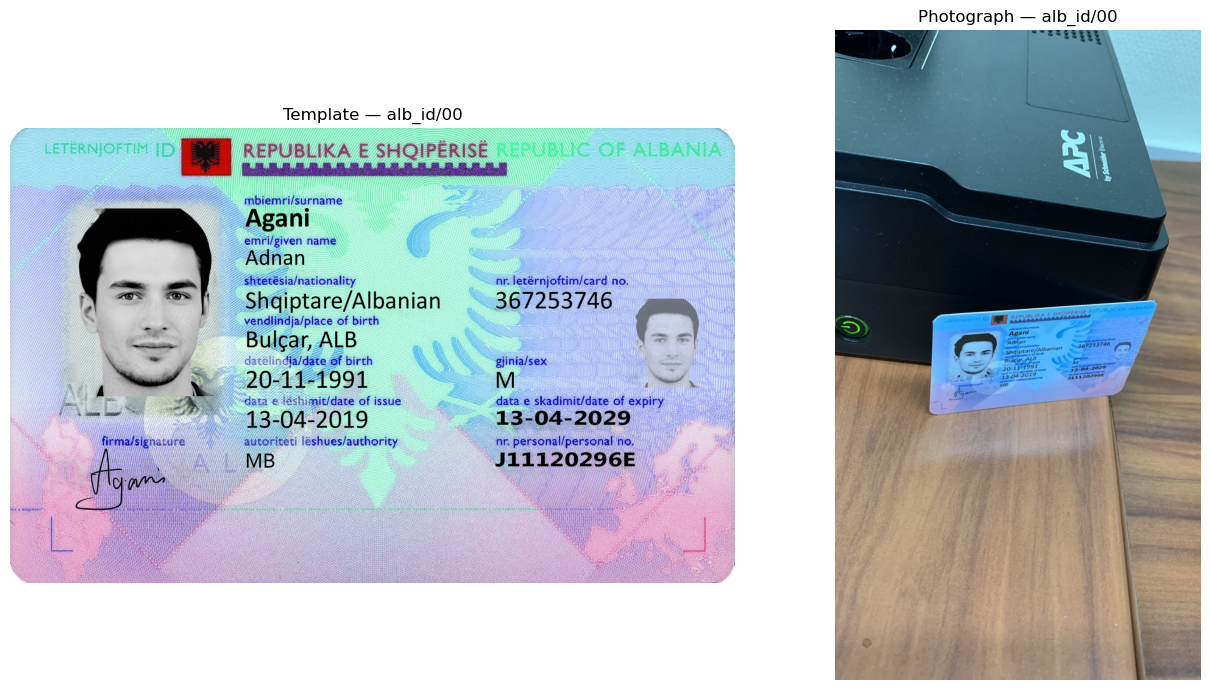

In [5]:
example_document_type = "alb_id"
example_filename = "00.jpg"
example_identity_key = make_identity_key(example_document_type, example_filename)

example_template_path = image_path(
    "templates", example_document_type, example_filename
)
example_photo_path = image_path("photo", example_document_type, example_filename)

with Image.open(example_template_path) as template_image, Image.open(example_photo_path) as photo_image:
    figure, axes = plt.subplots(1, 2, figsize=(14, 7))
    axes[0].imshow(template_image)
    axes[0].set_title(f"Template — {example_identity_key}")
    axes[1].imshow(photo_image)
    axes[1].set_title(f"Photograph — {example_identity_key}")
    for axis in axes:
        axis.axis("off")
    plt.tight_layout()
    plt.show()

### Inspect annotation anatomy before abstracting it

The photo annotation and template annotation serve different purposes. In this dataset copy, photo annotations contain the document quadrilateral (and face region), while template annotations contain the detailed field rectangles and ground-truth values.

In [6]:
photo_record = metadata_by_source["photo"][example_document_type][example_filename]
template_record = metadata_by_source["templates"][example_document_type][example_filename]

print("Photo fields:")
print([
    region.get("region_attributes", {}).get("field_name")
    for region in photo_record["regions"]
])

print("\nTemplate fields:")
print([
    region.get("region_attributes", {}).get("field_name")
    for region in template_record["regions"]
])

print("\nOne raw text region:")
text_region = next(
    region
    for region in template_record["regions"]
    if region.get("region_attributes", {}).get("value")
)
print(json.dumps(text_region, indent=2, ensure_ascii=False))

Photo fields:
['face', 'doc_quad']

Template fields:
['photo', 'signature', 'authority', 'birth_date', 'birth_place', 'issue_date', 'expiry_date', 'gender', 'id_number', 'name', 'nationality', 'number', 'surname', 'face']

One raw text region:
{
  "shape_attributes": {
    "name": "rect",
    "x": 708,
    "y": 973,
    "width": 82,
    "height": 43
  },
  "region_attributes": {
    "field_name": "authority",
    "value": "MB",
    "features": {}
  }
}


### Visual validation: photograph quadrilateral

Coordinates are image-space `(x, y)` points. Array indexing is usually `[y, x]`, but plotting uses `(x, y)`. Closing the polygon means repeating the first point at the end solely for drawing.

The dataset supplies these corners; at this stage we are validating our interpretation, not detecting the document ourselves.

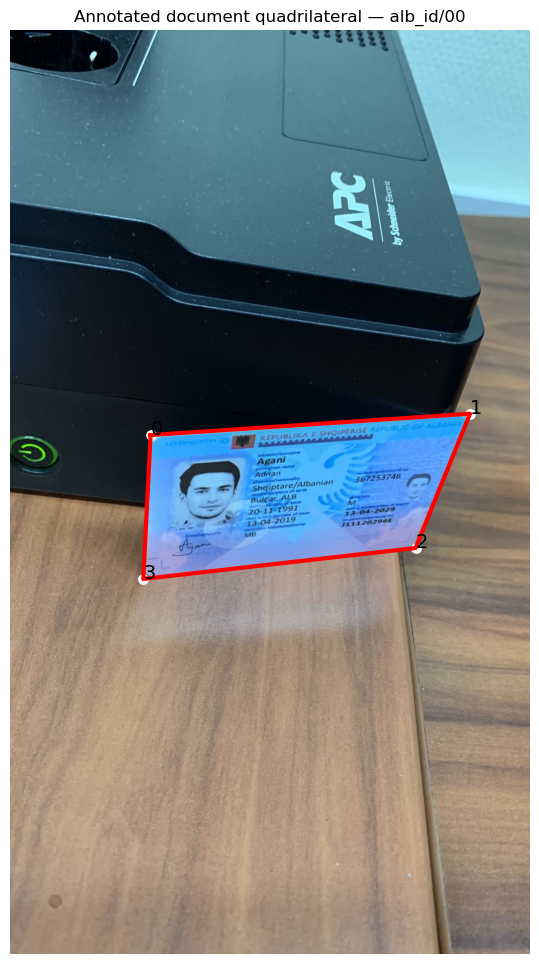

In [7]:
def document_corners(record):
    quadrilateral_regions = regions_named(record, "doc_quad")
    if len(quadrilateral_regions) != 1:
        raise ValueError(
            f"Expected one doc_quad, found {len(quadrilateral_regions)}"
        )

    shape = quadrilateral_regions[0]["shape_attributes"]
    x_coordinates = shape["all_points_x"]
    y_coordinates = shape["all_points_y"]
    corners = np.asarray(list(zip(x_coordinates, y_coordinates)), dtype=np.float64)

    if corners.shape != (4, 2):
        raise ValueError(f"Expected four (x, y) corners, got {corners.shape}")
    return corners


example_corners = document_corners(photo_record)
closed_corners = np.vstack([example_corners, example_corners[0]])

with Image.open(example_photo_path) as photo_image:
    figure, axis = plt.subplots(figsize=(8, 12))
    axis.imshow(photo_image)
    axis.plot(closed_corners[:, 0], closed_corners[:, 1], color="red", linewidth=3)
    axis.scatter(example_corners[:, 0], example_corners[:, 1], color="white", s=45)
    for corner_index, (x_coordinate, y_coordinate) in enumerate(example_corners):
        axis.text(x_coordinate, y_coordinate, str(corner_index), fontsize=14, color="black")
    axis.set_title(f"Annotated document quadrilateral — {example_identity_key}")
    axis.axis("off")
    plt.show()

### Visual validation: template field rectangles

This confirms that rectangle coordinates and field names refer to the locations we think they do. Empty values for `photo`, `face`, or `signature` are expected because those are visual regions, not target strings.

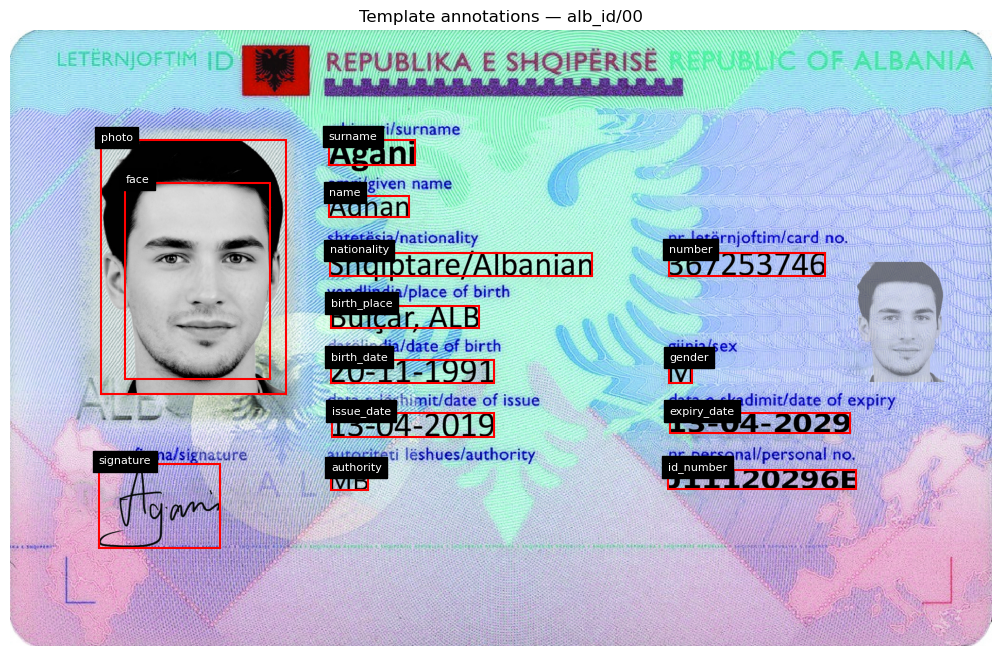

In [8]:
def show_template_annotations(document_type, filename, *, label_values=False):
    record = metadata_by_source["templates"][document_type][filename]
    path = image_path("templates", document_type, filename)

    with Image.open(path) as template_image:
        figure, axis = plt.subplots(figsize=(13, 8))
        axis.imshow(template_image)

        for region in record.get("regions", []):
            shape = region.get("shape_attributes", {})
            attributes = region.get("region_attributes", {})
            if shape.get("name") != "rect":
                continue

            x_coordinate = shape["x"]
            y_coordinate = shape["y"]
            width = shape["width"]
            height = shape["height"]
            field_name = attributes.get("field_name", "<missing field_name>")
            value = attributes.get("value", "<missing value>")
            label = f"{field_name}: {value}" if label_values else field_name

            axis.add_patch(
                Rectangle(
                    (x_coordinate, y_coordinate),
                    width,
                    height,
                    fill=False,
                    linewidth=1.5,
                    edgecolor="red",
                )
            )
            axis.text(
                x_coordinate,
                y_coordinate,
                label,
                fontsize=8,
                color="white",
                backgroundcolor="black",
            )

        axis.set_title(f"Template annotations — {make_identity_key(document_type, filename)}")
        axis.axis("off")
        plt.show()


show_template_annotations(example_document_type, example_filename)

## Investigation 10 — Determine available fields

Seeing one field once proves only that it exists in one annotation. We need **sample coverage**: in how many of the 100 identities does each raw field appear?

We use template annotations because they contain the detailed text fields. We retain MIDV's raw names. Mapping `name → given_names`, `gender → sex`, or `number/id_number → document_number` is a separate semantic decision and must not be silently baked into dataset loading.

In [9]:
# First, reproduce the simple Counter approach for one document type.
example_field_counts = Counter()

for record in metadata_by_source["templates"][example_document_type].values():
    for region in record.get("regions", []):
        field_name = region.get("region_attributes", {}).get("field_name")
        if field_name:
            example_field_counts[field_name] += 1

pd.Series(example_field_counts, name="annotated_regions").sort_index().to_frame()

,annotated_regions
authority,100
birth_date,100
birth_place,100
expiry_date,100
face,100
gender,100
id_number,100
issue_date,100
name,100
nationality,100


### Normalize regions into a tidy table

One row below means **one annotated region**, not one image. A tidy table makes grouping explicit and reusable across later investigations.

In [10]:
def build_region_table(source, document_types):
    rows = []
    for document_type in document_types:
        records = metadata_by_source[source][document_type]
        for filename, record in records.items():
            for region_index, region in enumerate(record.get("regions", [])):
                shape = region.get("shape_attributes", {})
                attributes = region.get("region_attributes", {})
                value_key_present = "value" in attributes
                value = attributes.get("value")
                rows.append(
                    {
                        "source": source,
                        "document_type": document_type,
                        "filename": filename,
                        "sample_id": Path(filename).stem,
                        "identity_key": make_identity_key(document_type, filename),
                        "region_index": region_index,
                        "field_name": attributes.get("field_name"),
                        "value_key_present": value_key_present,
                        "value": value,
                        "shape_name": shape.get("name"),
                        "x": shape.get("x"),
                        "y": shape.get("y"),
                        "width": shape.get("width"),
                        "height": shape.get("height"),
                        "features": attributes.get("features", {}),
                    }
                )
    return pd.DataFrame(rows)


template_regions = build_region_table("templates", card_document_types)
photo_regions = build_region_table("photo", card_document_types)

template_regions.head()

,source,document_type,filename,sample_id,identity_key,region_index,field_name,value_key_present,value,shape_name,x,y,width,height,features
0,templates,alb_id,00.jpg,00,alb_id/00,0,photo,True,,rect,200,243,409,560,{}
1,templates,alb_id,00.jpg,00,alb_id/00,1,signature,True,,rect,195,958,268,185,{}
2,templates,alb_id,00.jpg,00,alb_id/00,2,authority,True,MB,rect,708,973,82,43,{}
3,templates,alb_id,00.jpg,00,alb_id/00,3,birth_date,True,20-11-1991,rect,708,727,360,52,{}
4,templates,alb_id,00.jpg,00,alb_id/00,4,birth_place,True,"Bulçar, ALB",rect,708,608,327,50,"{'lowercase': True, 'descenders': True, 'ascen..."


In [11]:
# Count identities containing each field, not merely raw region occurrences.
field_sample_counts = (
    template_regions.dropna(subset=["field_name"])
    .groupby(["field_name", "document_type"])["identity_key"]
    .nunique()
    .unstack(fill_value=0)
    .reindex(columns=card_document_types)
    .sort_index()
)

field_sample_counts

document_type,alb_id,esp_id,est_id,fin_id,svk_id
field_name,,,,,
authority,100,0,0,0,0
birth_date,100,100,100,100,100
birth_date_2,0,0,0,100,0
birth_date_22,0,0,0,100,0
birth_place,100,0,0,0,0
code,0,0,0,100,0
expiry_date,100,100,100,100,100
face,100,100,100,100,100
gender,100,100,100,100,100


In [12]:
sample_counts_by_type = pd.Series(
    {
        document_type: len(metadata_by_source["templates"][document_type])
        for document_type in card_document_types
    },
    name="samples",
)

field_coverage_percent = field_sample_counts.divide(
    sample_counts_by_type, axis="columns"
).mul(100)

field_coverage_percent.style.format("{:.0f}%")

document_type,alb_id,esp_id,est_id,fin_id,svk_id
field_name,,,,,
authority,100%,0%,0%,0%,0%
birth_date,100%,100%,100%,100%,100%
birth_date_2,0%,0%,0%,100%,0%
birth_date_22,0%,0%,0%,100%,0%
birth_place,100%,0%,0%,0%,0%
code,0%,0%,0%,100%,0%
expiry_date,100%,100%,100%,100%,100%
face,100%,100%,100%,100%,100%
gender,100%,100%,100%,100%,100%


### Coverage is not the same as annotation multiplicity

If a field appeared twice in every image, a naïve region count would be 200 while sample coverage would still be 100. The following diagnostic finds repeated field labels within the same sample.

In [13]:
duplicate_field_regions = (
    template_regions.dropna(subset=["field_name"])
    .groupby(["document_type", "identity_key", "field_name"])
    .size()
    .rename("regions_with_same_field_name")
    .reset_index()
    .query("regions_with_same_field_name > 1")
)

print(f"Sample/field combinations with duplicate regions: {len(duplicate_field_regions)}")
duplicate_field_regions.head(20)

Sample/field combinations with duplicate regions: 0


,document_type,identity_key,field_name,regions_with_same_field_name


### Raw dataset labels versus the future canonical schema

The roadmap's candidate schema and MIDV's labels are not identical:

| Project concept | Possible MIDV label(s) | Decision still required |
|---|---|---|
| given names | `name` | Confirm semantics on each selected layout |
| sex | `gender` | Choose canonical key and value normalization |
| document number | `number`, `id_number`, perhaps numbered variants | Determine which printed number is the desired document identifier |
| surname | `surname`, sometimes `surname_second` | Decide whether/how to combine multiple surnames |

We must inspect values and locations before defining aliases. Renaming fields only because their labels look similar could corrupt the ground truth.

In [14]:
example_values_by_type = (
    template_regions.query("filename == '00.jpg'")
    .loc[:, ["document_type", "field_name", "value"]]
    .sort_values(["document_type", "field_name"])
)

example_values_by_type

,document_type,field_name,value
2,alb_id,authority,MB
3,alb_id,birth_date,20-11-1991
4,alb_id,birth_place,"Bulçar, ALB"
6,alb_id,expiry_date,13-04-2029
13,alb_id,face,
...,...,...,...
5505,svk_id,nationality,SVK
5507,svk_id,number,EU394022
5500,svk_id,photo,
5501,svk_id,signature,


## Investigation 11 — “Missing” does not have only one meaning

At least four states matter:

1. **Annotation absent:** no region with that `field_name` exists for the sample.
2. **Value key missing:** the region exists, but `region_attributes` has no `value` key.
3. **Present but empty:** the key exists and `value == ""`.
4. **Present and non-empty:** the region exists and has a usable ground-truth string.

There is also a fifth anomaly: duplicate annotations for the same field in one sample.

An absent field across all samples of a type is *consistent with* structural absence, but the JSON alone does not prove that the physical layout lacks the concept. We verify the template and dataset documentation before calling it structurally absent.

In [15]:
for field_name in ("surname", "photo"):
    example_row = template_regions.query(
        "document_type == @example_document_type and filename == @example_filename and field_name == @field_name"
    ).iloc[0]
    print(
        f"{field_name!r}: value_key_present={example_row['value_key_present']}, "
        f"value={example_row['value']!r}"
    )

'surname': value_key_present=True, value='Agani'
'photo': value_key_present=True, value=''


In [16]:
def classify_field_state(regions):
    '''Classify a list of regions for one sample and one expected raw field.'''
    if not regions:
        return "annotation_absent"
    if len(regions) > 1:
        return "duplicate_annotations"

    attributes = regions[0].get("region_attributes", {})
    if "value" not in attributes:
        return "value_key_missing"
    if attributes["value"] == "":
        return "value_empty"
    return "value_nonempty"


all_raw_template_fields = sorted(
    field_name
    for field_name in template_regions["field_name"].dropna().unique()
)

field_state_rows = []
for document_type in card_document_types:
    for filename, record in metadata_by_source["templates"][document_type].items():
        for field_name in all_raw_template_fields:
            matching_regions = regions_named(record, field_name)
            field_state_rows.append(
                {
                    "document_type": document_type,
                    "filename": filename,
                    "identity_key": make_identity_key(document_type, filename),
                    "field_name": field_name,
                    "state": classify_field_state(matching_regions),
                }
            )

field_states = pd.DataFrame(field_state_rows)

field_state_summary = (
    field_states.groupby(["document_type", "field_name", "state"])
    .size()
    .rename("samples")
    .reset_index()
)

field_state_summary.query(
    "field_name in ['surname', 'name', 'birth_date', 'expiry_date', "
    "'nationality', 'gender', 'number', 'id_number', 'photo', 'signature']"
).sort_values(["field_name", "document_type", "state"])

,document_type,field_name,state,samples
1,alb_id,birth_date,value_nonempty,100
23,esp_id,birth_date,value_nonempty,100
45,est_id,birth_date,value_nonempty,100
67,fin_id,birth_date,value_nonempty,100
89,svk_id,birth_date,value_nonempty,100
6,alb_id,expiry_date,value_nonempty,100
28,esp_id,expiry_date,value_nonempty,100
50,est_id,expiry_date,value_nonempty,100
72,fin_id,expiry_date,value_nonempty,100
94,svk_id,expiry_date,value_nonempty,100


### Scoring consequence

Later evaluation should carry an explicit ground-truth applicability mask:

- A truly non-applicable field is excluded from that document type's denominator.
- A required field with an empty or defective annotation should be flagged and handled by a documented data-quality rule.
- A required, non-empty ground truth paired with an empty prediction is an extraction failure.

Do not encode all three situations as the same empty string.

## Investigation 12 — Determine image properties

Pillow reports image size as `(width, height)`. NumPy arrays report shape as `(height, width, channels)`. This reversal is a common source of coordinate bugs.

We inspect every image instead of assuming the documentation matches the local files. `with Image.open(...)` closes file handles promptly.

In [17]:
def build_image_table(sources, document_types):
    rows = []
    for source in sources:
        for document_type in document_types:
            directory = dataset_root / source / "images" / document_type
            for path in sorted(directory.glob("*")):
                if not path.is_file():
                    continue
                with Image.open(path) as image:
                    rows.append(
                        {
                            "source": source,
                            "document_type": document_type,
                            "filename": path.name,
                            "sample_id": path.stem,
                            "identity_key": make_identity_key(document_type, path.name),
                            "path": path,
                            "width": image.width,
                            "height": image.height,
                            "mode": image.mode,
                            "format": image.format,
                        }
                    )
    return pd.DataFrame(rows)


image_table = build_image_table(("templates", "photo"), card_document_types)

image_property_counts = (
    image_table.groupby(["source", "width", "height", "mode", "format"])
    .size()
    .rename("images")
    .reset_index()
    .sort_values(["source", "images"], ascending=[True, False])
)

image_property_counts

,source,width,height,mode,format,images
0,photo,2268,4032,RGB,JPEG,250
1,photo,4032,2268,RGB,JPEG,250
2,templates,929,580,CMYK,JPEG,100
3,templates,931,584,CMYK,JPEG,100
4,templates,1134,716,RGB,JPEG,100
5,templates,1327,827,CMYK,JPEG,100
6,templates,2167,1360,CMYK,JPEG,100


In [18]:
with Image.open(example_photo_path) as pil_image:
    image_array = np.asarray(pil_image)
    print(f"Pillow size (width, height):       {pil_image.size}")
    print(f"NumPy shape (height, width, ...): {image_array.shape}")
    print(f"Mode: {pil_image.mode}; format: {pil_image.format}; dtype: {image_array.dtype}")

Pillow size (width, height):       (2268, 4032)
NumPy shape (height, width, ...): (4032, 2268, 3)
Mode: RGB; format: JPEG; dtype: uint8


### Interpretation checkpoint

Do not expect only one `(width, height)` tuple: portrait and landscape JPEGs can contain the same two dimensions in opposite order. Template sizes also vary by document layout. Record observed counts rather than forcing every image into the documentation's most familiar orientation.

## Investigation 13 — How large is the document inside the photograph?

The annotated `doc_quad` is a polygon. Its area can be calculated with the shoelace formula. OpenCV's `cv2.contourArea` is equivalent for this purpose, but NumPy keeps Phase 1 independent of an OpenCV installation.

The ratio

`annotated polygon area / image area`

is a first geometric feature. It is not a complete quality measure: it says nothing about blur, glare, focus, or readable character height.

In [19]:
def polygon_area(points):
    '''Return the unsigned area of a 2D polygon using the shoelace formula.'''
    points = np.asarray(points, dtype=np.float64)
    x_coordinates = points[:, 0]
    y_coordinates = points[:, 1]
    return 0.5 * abs(
        np.dot(x_coordinates, np.roll(y_coordinates, -1))
        - np.dot(y_coordinates, np.roll(x_coordinates, -1))
    )


photo_dimensions = (
    image_table.query("source == 'photo'")
    .set_index(["document_type", "filename"])[["width", "height"]]
)

geometry_rows = []
for document_type in card_document_types:
    for filename, record in metadata_by_source["photo"][document_type].items():
        width, height = photo_dimensions.loc[(document_type, filename)]
        corners = document_corners(record)
        annotated_area = polygon_area(corners)
        image_area = float(width * height)

        x_coordinates = corners[:, 0]
        y_coordinates = corners[:, 1]
        corner_outside_image = bool(
            (x_coordinates < 0).any()
            or (x_coordinates > width).any()
            or (y_coordinates < 0).any()
            or (y_coordinates > height).any()
        )

        geometry_rows.append(
            {
                "document_type": document_type,
                "filename": filename,
                "sample_id": Path(filename).stem,
                "identity_key": make_identity_key(document_type, filename),
                "image_width": width,
                "image_height": height,
                "document_area_pixels": annotated_area,
                "image_area_pixels": image_area,
                "relative_document_area": annotated_area / image_area,
                "corner_outside_image": corner_outside_image,
                "degenerate_quad": annotated_area <= 0,
            }
        )

photo_geometry = pd.DataFrame(geometry_rows)

photo_geometry.groupby("document_type")["relative_document_area"].describe().round(4)

,count,mean,std,min,25%,50%,75%,max
document_type,,,,,,,,
alb_id,100.0,0.1555,0.0542,0.0491,0.1102,0.1525,0.1943,0.2773
esp_id,100.0,0.1495,0.0542,0.0289,0.1088,0.1453,0.1921,0.2711
est_id,100.0,0.1400,0.0491,0.0297,0.1051,0.1288,0.1720,0.2497
fin_id,100.0,0.1374,0.0475,0.0306,0.1003,0.1280,0.1595,0.2899
svk_id,100.0,0.1568,0.0560,0.0363,0.1113,0.1539,0.2012,0.2837


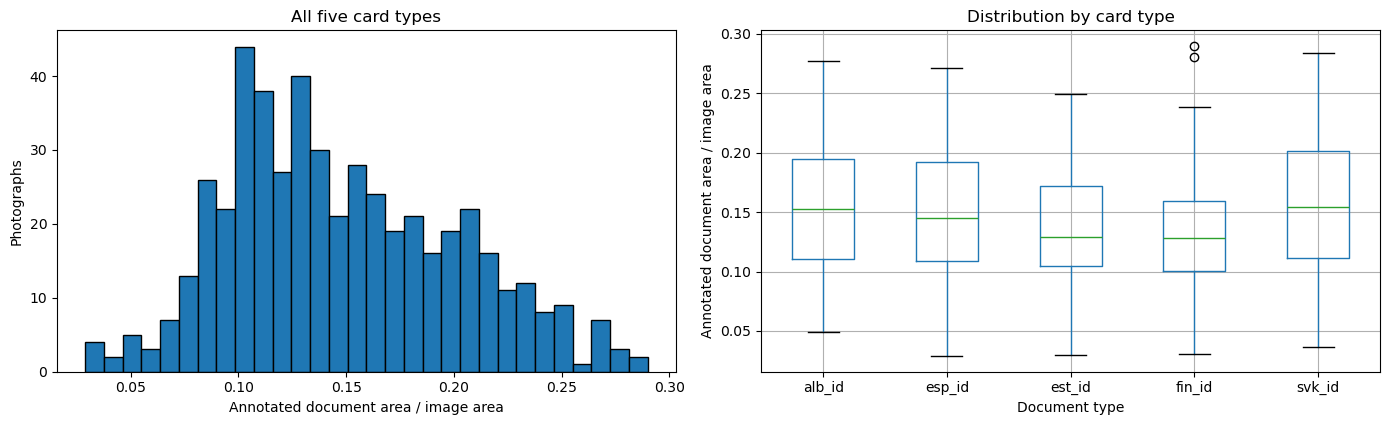

In [20]:
figure, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].hist(photo_geometry["relative_document_area"], bins=30, edgecolor="black")
axes[0].set_xlabel("Annotated document area / image area")
axes[0].set_ylabel("Photographs")
axes[0].set_title("All five card types")

photo_geometry.boxplot(column="relative_document_area", by="document_type", ax=axes[1])
axes[1].set_xlabel("Document type")
axes[1].set_ylabel("Annotated document area / image area")
axes[1].set_title("Distribution by card type")
figure.suptitle("")

plt.tight_layout()
plt.show()

### Important boundary finding

Some annotated quadrilaterals extend outside the image. That can be legitimate when part of the physical document is outside the camera frame; it is not automatically an annotation error. Therefore:

- `document_area_pixels` is the area of the **annotated full polygon**;
- it is not necessarily the visible, clipped area;
- `corner_outside_image` should be retained as a diagnostic feature;
- a later visible-area feature would require clipping the polygon to the image rectangle.

This is why we measure first and assert later.

In [21]:
photo_geometry.groupby("document_type").agg(
    photographs=("identity_key", "size"),
    quads_with_outside_corner=("corner_outside_image", "sum"),
    degenerate_quads=("degenerate_quad", "sum"),
)

,photographs,quads_with_outside_corner,degenerate_quads
document_type,,,
alb_id,100,37,0
esp_id,100,33,0
est_id,100,27,0
fin_id,100,32,0
svk_id,100,39,0


## Investigation 14 — Understand MIDV's capture conditions

For still photographs, sample number deterministically encodes both phone and constructed capture condition. The mapping below comes from the dataset's published capture table and should be cited from that source in the final report.

| IDs | Device | Condition |
|---|---|---|
| 00–09 | iPhone XR | projective distortion |
| 10–19 | Samsung Galaxy S10 | projective distortion |
| 20–24 | iPhone XR | text background |
| 25–29 | Samsung Galaxy S10 | text background |
| 30–34 | iPhone XR | keyboard background |
| 35–39 | Samsung Galaxy S10 | keyboard background |
| 40–44 | iPhone XR | outdoors |
| 45–49 | Samsung Galaxy S10 | outdoors |
| 50–54 | iPhone XR | table background |
| 55–59 | Samsung Galaxy S10 | table background |
| 60–64 | iPhone XR | highlights/reflections |
| 65–69 | Samsung Galaxy S10 | highlights/reflections |
| 70–79 | iPhone XR | low light |
| 80–89 | Samsung Galaxy S10 | low light |
| 90–94 | iPhone XR | cloth background |
| 95–99 | Samsung Galaxy S10 | cloth background |

In [22]:
capture_ranges = (
    (0, 9, "iPhone XR", "projective distortion"),
    (10, 19, "Samsung Galaxy S10", "projective distortion"),
    (20, 24, "iPhone XR", "text background"),
    (25, 29, "Samsung Galaxy S10", "text background"),
    (30, 34, "iPhone XR", "keyboard background"),
    (35, 39, "Samsung Galaxy S10", "keyboard background"),
    (40, 44, "iPhone XR", "outdoors"),
    (45, 49, "Samsung Galaxy S10", "outdoors"),
    (50, 54, "iPhone XR", "table background"),
    (55, 59, "Samsung Galaxy S10", "table background"),
    (60, 64, "iPhone XR", "highlights/reflections"),
    (65, 69, "Samsung Galaxy S10", "highlights/reflections"),
    (70, 79, "iPhone XR", "low light"),
    (80, 89, "Samsung Galaxy S10", "low light"),
    (90, 94, "iPhone XR", "cloth background"),
    (95, 99, "Samsung Galaxy S10", "cloth background"),
)


def capture_metadata(sample_id):
    '''Decode the published still-photo capture table from sample ID 00–99.'''
    numeric_id = int(sample_id)
    matches = [
        (device, condition)
        for lower, upper, device, condition in capture_ranges
        if lower <= numeric_id <= upper
    ]
    if len(matches) != 1:
        raise ValueError(f"Sample ID {sample_id!r} has {len(matches)} capture mappings")
    device, condition = matches[0]
    return {"device": device, "capture_condition": condition}


capture_rows = []
for sample_id in (f"{number:02d}" for number in range(100)):
    capture_rows.append({"sample_id": sample_id, **capture_metadata(sample_id)})
capture_table = pd.DataFrame(capture_rows)

pd.crosstab(capture_table["capture_condition"], capture_table["device"])

device,Samsung Galaxy S10,iPhone XR
capture_condition,,
cloth background,5,5
highlights/reflections,5,5
keyboard background,5,5
low light,10,10
outdoors,5,5
projective distortion,10,10
table background,5,5
text background,5,5


In [23]:
photo_geometry_with_capture = photo_geometry.merge(
    capture_table, on="sample_id", validate="many_to_one"
)

photo_geometry_with_capture.groupby(
    ["capture_condition", "device"]
)["relative_document_area"].agg(["count", "median", "min", "max"]).round(4)

count  median     min     max
capture_condition      device                                           
cloth background       Samsung Galaxy S10     25  0.1755  0.1154  0.2426
                       iPhone XR              25  0.1653  0.0933  0.2492
highlights/reflections Samsung Galaxy S10     25  0.1321  0.0638  0.2463
                       iPhone XR              25  0.1092  0.0686  0.1963
keyboard background    Samsung Galaxy S10     25  0.2071  0.1261  0.2899
                       iPhone XR              25  0.1011  0.0661  0.2053
low light              Samsung Galaxy S10     50  0.2078  0.0850  0.2773
                       iPhone XR              50  0.1949  0.0889  0.2658
outdoors               Samsung Galaxy S10     25  0.1746  0.1002  0.2584
                       iPhone XR              25  0.1005  0.0491  0.1717
projective distortion  Samsung Galaxy S10     50  0.1161  0.0710  0.2497
                       iPhone XR              50  0.1226  0.0790  0.2006
table background       Samsung Galaxy S10     25  0.1012  0.0306  0.2837
                       iPhone XR              25  0.1098  0.0289  0.2724
text background        Samsung Galaxy S10     25  0.1285  0.0922  0.2031
                       iPhone XR              25  0.1206  0.0789  0.1901

### Research-design limitation: condition is confounded with identity

For a given document type, identity `03` appears in one still-photo condition; there is no matching still photo of identity `03` under every other condition. Therefore a difference between low-light and outdoor groups can also reflect differences in the identities assigned to those groups.

We may report performance **stratified by capture condition**, but we should not describe the still-photo comparison as a controlled repeated-measures experiment. Synthetic degradations later provide controlled within-identity comparisons.

## Investigation 15 — Evaluation unit and leakage

The stable evaluation unit is the underlying identity key:

`document_type/sample_id`

Template, photograph, future scan, and every synthetic degradation derived from one key must share a split. The split is assigned to identities first, then inherited by observations.

In [24]:
observations = image_table.loc[
    :, ["source", "document_type", "filename", "sample_id", "identity_key"]
].copy()

observation_summary = observations.groupby("identity_key").agg(
    observations=("source", "size"),
    sources=("source", lambda values: tuple(sorted(values))),
)

observation_summary.head()

,observations,sources
identity_key,,
alb_id/00,2,"(photo, templates)"
alb_id/01,2,"(photo, templates)"
alb_id/02,2,"(photo, templates)"
alb_id/03,2,"(photo, templates)"
alb_id/04,2,"(photo, templates)"


In [25]:
def make_identity_splits(document_types, seed=2026):
    '''Create exact 70/15/15 splits, stratified by document type.'''
    random_generator = np.random.default_rng(seed)
    assignments = []

    for document_type in document_types:
        identity_keys = sorted(
            {
                make_identity_key(document_type, filename)
                for filename in metadata_by_source["templates"][document_type]
            }
        )
        shuffled_keys = np.asarray(identity_keys, dtype=object)
        random_generator.shuffle(shuffled_keys)

        number_of_identities = len(shuffled_keys)
        train_end = int(0.70 * number_of_identities)
        validation_end = train_end + int(0.15 * number_of_identities)

        for index, identity_key in enumerate(shuffled_keys):
            if index < train_end:
                split = "train"
            elif index < validation_end:
                split = "validation"
            else:
                split = "test"
            assignments.append(
                {
                    "document_type": document_type,
                    "identity_key": identity_key,
                    "split": split,
                }
            )

    return pd.DataFrame(assignments)


# This demonstrates the rule. Persist the final assignment only after scope is frozen.
provisional_identity_splits = make_identity_splits(card_document_types)
provisional_observation_splits = observations.merge(
    provisional_identity_splits,
    on=["document_type", "identity_key"],
    validate="many_to_one",
)

split_counts = (
    provisional_identity_splits.groupby(["document_type", "split"])["identity_key"]
    .nunique()
    .unstack(fill_value=0)
)

leaking_identities = (
    provisional_observation_splits.groupby("identity_key")["split"].nunique() > 1
).sum()

print(f"Identities assigned to more than one split: {leaking_identities}")
split_counts

Identities assigned to more than one split: 0


split,test,train,validation
document_type,,,
alb_id,15,70,15
esp_id,15,70,15
est_id,15,70,15
fin_id,15,70,15
svk_id,15,70,15


### Why the split is provisional

The code demonstrates a leakage-safe mechanism, but we should not save a final split manifest until we decide whether the first experiment uses one card type or several. Once saved and used for reported experiments, the seed and manifest become part of the experimental contract and should not be repeatedly changed to obtain favorable results.

## Investigation 16 — Evidence for selecting the first document type

We compare the five planar card layouts transparently. A single “suitability score” would hide judgment calls about which characteristics matter.

The table separates textual fields from visual regions. It also reports **possible vertical-text candidates** using a conservative heuristic:

- median rectangle height/width greater than 1.5; and
- median non-empty value length greater than 2 characters.

This is only a shortlist for visual inspection. A tall rectangle is not proof that its text is rotated, and narrow one-character fields such as gender can otherwise create false positives.

In [26]:
text_template_regions = template_regions.loc[
    ~template_regions["field_name"].isin(non_text_region_names)
    & template_regions["field_name"].notna()
].copy()

text_template_regions["box_aspect_height_over_width"] = (
    text_template_regions["height"] / text_template_regions["width"]
)
text_template_regions["value_length"] = (
    text_template_regions["value"].fillna("").astype(str).str.len()
)

field_geometry_summary = (
    text_template_regions.groupby(["document_type", "field_name"])
    .agg(
        annotated_samples=("identity_key", "nunique"),
        median_height_over_width=("box_aspect_height_over_width", "median"),
        median_value_length=("value_length", "median"),
    )
    .reset_index()
)

vertical_candidates = field_geometry_summary.query(
    "median_height_over_width > 1.5 and median_value_length > 2"
)

vertical_candidates

,document_type,field_name,annotated_samples,median_height_over_width,median_value_length
30,est_id,number3,100,7.0625,9.0
34,fin_id,birth_date_22,100,4.1250,6.0


In [27]:
candidate_rows = []
for document_type in card_document_types:
    type_regions = template_regions.query("document_type == @document_type")
    type_text_regions = text_template_regions.query("document_type == @document_type")
    type_coverage = field_sample_counts[document_type]
    type_vertical_candidates = vertical_candidates.query(
        "document_type == @document_type"
    )["field_name"].tolist()
    template_dimensions = image_property_counts.query(
        "source == 'templates' and document_type == @document_type"
    ) if "document_type" in image_property_counts.columns else pd.DataFrame()

    # Obtain dimensions directly because image_property_counts intentionally aggregates
    # across document type when dimensions happen to match.
    dimension_pairs = sorted(
        {
            f"{row.width}×{row.height}"
            for row in image_table.query(
                "source == 'templates' and document_type == @document_type"
            ).itertuples()
        }
    )

    text_field_names = sorted(type_text_regions["field_name"].dropna().unique())
    complete_text_fields = [
        field_name
        for field_name in text_field_names
        if type_coverage.get(field_name, 0) == sample_counts_by_type[document_type]
    ]

    candidate_rows.append(
        {
            "document_type": document_type,
            "samples": len(metadata_by_source["templates"][document_type]),
            "all_annotated_fields": type_regions["field_name"].nunique(),
            "text_fields": len(text_field_names),
            "text_fields_in_every_sample": len(complete_text_fields),
            "empty_text_values": int((type_text_regions["value"] == "").sum()),
            "possible_vertical_fields": ", ".join(type_vertical_candidates) or "none",
            "template_dimensions": ", ".join(dimension_pairs),
        }
    )

candidate_document_table = pd.DataFrame(candidate_rows).set_index("document_type")
candidate_document_table

,samples,all_annotated_fields,text_fields,text_fields_in_every_sample,empty_text_values,possible_vertical_fields,template_dimensions
document_type,,,,,,,
alb_id,100,14,11,11,0,none,2167×1360
esp_id,100,14,11,11,0,none,1327×827
est_id,100,13,10,10,0,number3,929×580
fin_id,100,14,11,11,0,birth_date_22,931×584
svk_id,100,13,10,10,0,none,1134×716


### Inspect candidates visually instead of trusting heuristics

Use the function below with any document type and IDs selected from different capture conditions. Suggested IDs are `00` (projective distortion), `25` (text background), `70` (low light), and `95` (cloth background).

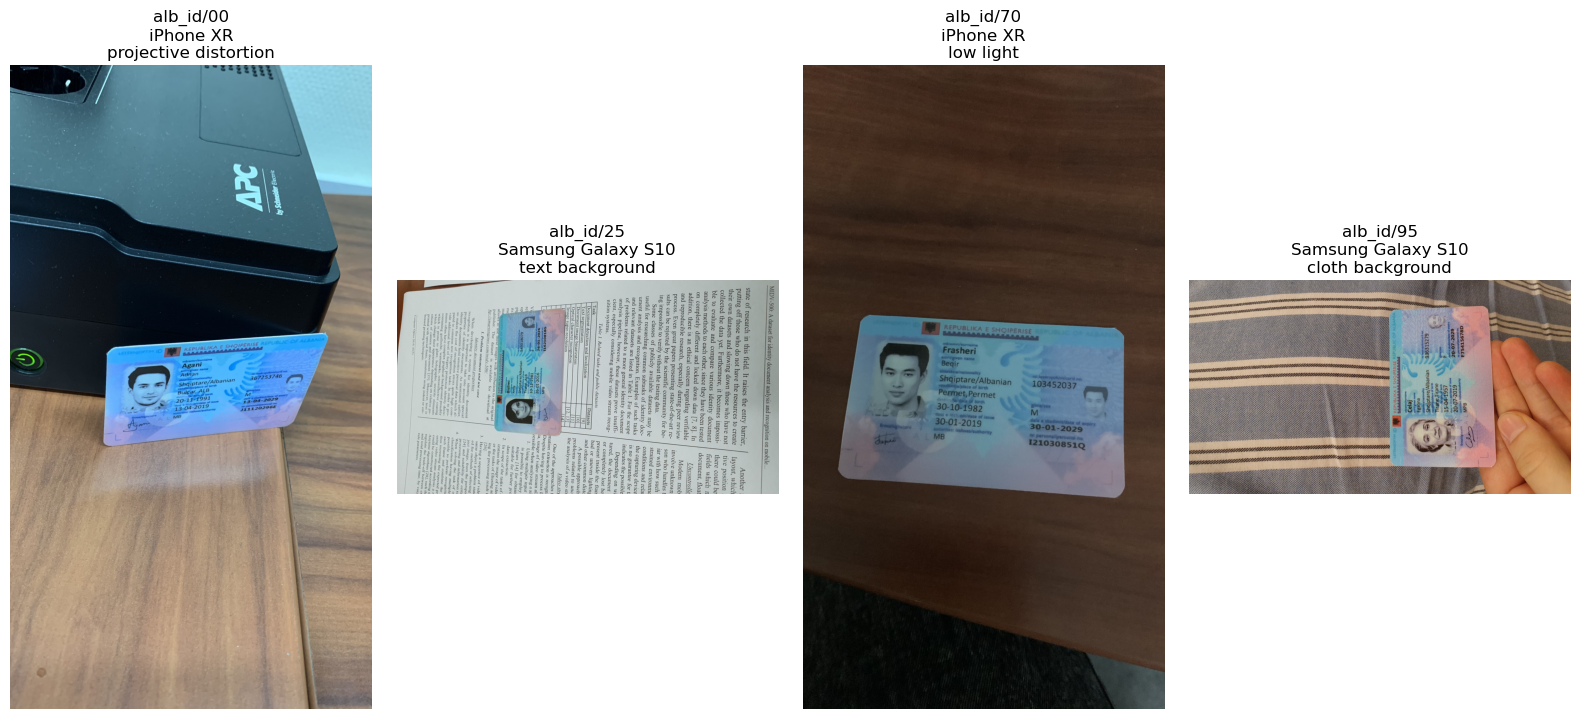

In [28]:
def show_photo_examples(document_type, sample_ids=("00", "25", "70", "95")):
    figure, axes = plt.subplots(1, len(sample_ids), figsize=(4 * len(sample_ids), 7))
    axes = np.atleast_1d(axes)

    for axis, sample_id in zip(axes, sample_ids):
        filename = f"{sample_id}.jpg"
        path = image_path("photo", document_type, filename)
        capture = capture_metadata(sample_id)
        with Image.open(path) as image:
            axis.imshow(image)
        axis.set_title(
            f"{document_type}/{sample_id}\n"
            f"{capture['device']}\n{capture['capture_condition']}"
        )
        axis.axis("off")

    plt.tight_layout()
    plt.show()


show_photo_examples("alb_id")

### Selection worksheet — complete after visual inspection

For each candidate, record:

- Which raw fields correspond unambiguously to the desired output?
- Are `number`, `id_number`, or numbered variants semantically clear?
- Are important text regions large enough to read after rectification?
- Is any important field vertical or otherwise unusually arranged?
- Are annotations complete and values non-empty?
- How complicated is the layout for a first prototype?
- Do names contain characters useful for testing Unicode handling?

Then choose one card type and write a short evidence-based rationale. Do not manufacture a weighted score for five candidates.

## Investigation 17 — Dataset limitations and measured sanity checks

Known design limitations must bound our claims:

- documents are mock identities with generated variable text, faces, and signatures;
- they were printed, laminated, and physically captured;
- still photos use two smartphone models and constructed capture conditions;
- the full dataset contains ten layouts with 100 identities each;
- each identity has only one still photograph, so condition and identity are confounded.

Accordingly, future conclusions should begin with **“On the tested MIDV-2020 workload…”**, not claim universal KYC performance.

The remaining limitations are empirical. We measure them below without assuming every unusual observation is an error.

### 17.1 — Annotation records versus image files

We compare filename sets in both directions. A file can lack an annotation, or an annotation can reference a missing file.

In [29]:
pairing_rows = []
for source in ("templates", "photo"):
    for document_type in card_document_types:
        annotation_filenames = set(metadata_by_source[source][document_type])
        image_filenames = {
            path.name
            for path in (dataset_root / source / "images" / document_type).glob("*")
            if path.is_file()
        }
        pairing_rows.append(
            {
                "source": source,
                "document_type": document_type,
                "annotation_records": len(annotation_filenames),
                "image_files": len(image_filenames),
                "annotations_without_image": len(annotation_filenames - image_filenames),
                "images_without_annotation": len(image_filenames - annotation_filenames),
            }
        )

pairing_checks = pd.DataFrame(pairing_rows)
pairing_checks

,source,document_type,annotation_records,image_files,annotations_without_image,images_without_annotation
0,templates,alb_id,100,100,0,0
1,templates,esp_id,100,100,0,0
2,templates,est_id,100,100,0,0
3,templates,fin_id,100,100,0,0
4,templates,svk_id,100,100,0,0
5,photo,alb_id,100,100,0,0
6,photo,esp_id,100,100,0,0
7,photo,est_id,100,100,0,0
8,photo,fin_id,100,100,0,0
9,photo,svk_id,100,100,0,0


### 17.2 — Rectangle geometry in template annotations

We check negative origins, non-positive sizes, and rectangles extending beyond image boundaries. We report counts first; we do not crash on the first exception.

In [30]:
template_dimension_lookup = (
    image_table.query("source == 'templates'")
    .set_index(["document_type", "filename"])[["width", "height"]]
)

rectangle_checks = template_regions.query("shape_name == 'rect'").copy()
rectangle_checks = rectangle_checks.join(
    template_dimension_lookup,
    on=["document_type", "filename"],
    rsuffix="_image",
)
rectangle_checks["negative_origin"] = (
    (rectangle_checks["x"] < 0) | (rectangle_checks["y"] < 0)
)
rectangle_checks["nonpositive_size"] = (
    (rectangle_checks["width"] <= 0) | (rectangle_checks["height"] <= 0)
)
rectangle_checks["extends_beyond_image"] = (
    (rectangle_checks["x"] + rectangle_checks["width"] > rectangle_checks["width_image"])
    | (rectangle_checks["y"] + rectangle_checks["height"] > rectangle_checks["height_image"])
)
rectangle_checks["relative_box_area"] = (
    rectangle_checks["width"]
    * rectangle_checks["height"]
    / (rectangle_checks["width_image"] * rectangle_checks["height_image"])
)

rectangle_checks.groupby("document_type").agg(
    rectangles=("region_index", "size"),
    negative_origins=("negative_origin", "sum"),
    nonpositive_sizes=("nonpositive_size", "sum"),
    rectangles_beyond_image=("extends_beyond_image", "sum"),
    smallest_relative_box=("relative_box_area", "min"),
).round(6)

,rectangles,negative_origins,nonpositive_sizes,rectangles_beyond_image,smallest_relative_box
document_type,,,,,
alb_id,1400,0,0,0,0.000399
esp_id,1400,0,0,0,0.000465
est_id,1300,0,0,0,0.001516
fin_id,1400,0,0,0,0.000456
svk_id,1300,0,0,0,0.000749


### 17.3 — Empty and missing values

Empty values are not uniformly errors. Visual regions deliberately have no transcription. We summarize text and non-text regions separately.

In [31]:
value_quality = template_regions.assign(
    region_role=np.where(
        template_regions["field_name"].isin(non_text_region_names),
        "non_text_visual_region",
        "candidate_text_field",
    ),
    value_state=np.select(
        [
            ~template_regions["value_key_present"],
            template_regions["value"].eq(""),
            template_regions["value"].notna(),
        ],
        ["value_key_missing", "value_empty", "value_nonempty"],
        default="value_is_null",
    ),
)

pd.crosstab(
    [value_quality["document_type"], value_quality["region_role"]],
    value_quality["value_state"],
)

value_state                           value_empty  value_nonempty
document_type region_role                                        
alb_id        candidate_text_field              0            1100
              non_text_visual_region          300               0
esp_id        candidate_text_field              0            1100
              non_text_visual_region          300               0
est_id        candidate_text_field              0            1000
              non_text_visual_region          300               0
fin_id        candidate_text_field              0            1100
              non_text_visual_region          300               0
svk_id        candidate_text_field              0            1000
              non_text_visual_region          300               0

### 17.4 — Duplicate and low-diversity field values

Repeated values are not automatically duplicates or errors: nationality, dates, and gender can legitimately repeat. Low uniqueness is a diagnostic that tells us where naive random splitting or memorization could be misleading.

In [32]:
nonempty_text_values = text_template_regions.loc[
    text_template_regions["value"].notna() & text_template_regions["value"].ne("")
].copy()

value_diversity = (
    nonempty_text_values.groupby(["document_type", "field_name"])["value"]
    .agg(nonempty_values="count", unique_values="nunique")
    .reset_index()
)
value_diversity["unique_fraction"] = (
    value_diversity["unique_values"] / value_diversity["nonempty_values"]
)

value_diversity.sort_values(
    ["unique_fraction", "document_type", "field_name"]
).head(30)

,document_type,field_name,nonempty_values,unique_values,unique_fraction
8,alb_id,nationality,100,1,0.01
18,esp_id,nationality,100,1,0.01
40,fin_id,nationality,100,1,0.01
50,svk_id,nationality,100,1,0.01
0,alb_id,authority,100,2,0.02
4,alb_id,gender,100,2,0.02
13,esp_id,gender,100,2,0.02
24,est_id,gender,100,2,0.02
37,fin_id,gender,100,2,0.02
45,svk_id,gender,100,2,0.02


### 17.5 — Quad and dimension diagnostics

Unexpected dimensions, outside corners, or very small document-area ratios deserve visual inspection. Outside corners are not automatically invalid, as Investigation 13 showed.

In [33]:
quad_diagnostics = photo_geometry.groupby("document_type").agg(
    photographs=("identity_key", "size"),
    outside_corner_quads=("corner_outside_image", "sum"),
    degenerate_quads=("degenerate_quad", "sum"),
    minimum_relative_area=("relative_document_area", "min"),
    median_relative_area=("relative_document_area", "median"),
    maximum_relative_area=("relative_document_area", "max"),
).round(4)

quad_diagnostics

,photographs,outside_corner_quads,degenerate_quads,minimum_relative_area,median_relative_area,maximum_relative_area
document_type,,,,,,
alb_id,100,37,0,0.0491,0.1525,0.2773
esp_id,100,33,0,0.0289,0.1453,0.2711
est_id,100,27,0,0.0297,0.1288,0.2497
fin_id,100,32,0,0.0306,0.1280,0.2899
svk_id,100,39,0,0.0363,0.1539,0.2837


In [34]:
dimension_diagnostics = (
    image_table.groupby(["source", "document_type", "width", "height", "mode", "format"])
    .size()
    .rename("images")
    .reset_index()
    .sort_values(["source", "document_type", "images"], ascending=[True, True, False])
)

dimension_diagnostics

,source,document_type,width,height,mode,format,images
0,photo,alb_id,2268,4032,RGB,JPEG,50
1,photo,alb_id,4032,2268,RGB,JPEG,50
2,photo,esp_id,2268,4032,RGB,JPEG,50
3,photo,esp_id,4032,2268,RGB,JPEG,50
4,photo,est_id,2268,4032,RGB,JPEG,50
5,photo,est_id,4032,2268,RGB,JPEG,50
6,photo,fin_id,2268,4032,RGB,JPEG,50
7,photo,fin_id,4032,2268,RGB,JPEG,50
8,photo,svk_id,2268,4032,RGB,JPEG,50
9,photo,svk_id,4032,2268,RGB,JPEG,50


### 17.6 — Optional exact duplicate-image check

Cryptographic hashing reads every byte of every image and may take time on the full dataset. It is disabled by default so ordinary notebook execution remains lightweight. Enable it deliberately when you want to audit byte-for-byte duplicates. Identical-looking recompressed images will not share a hash; perceptual duplicate detection is a separate task.

In [35]:
RUN_EXPENSIVE_DUPLICATE_IMAGE_CHECK = False


def file_sha256(path, chunk_size=1024 * 1024):
    digest = sha256()
    with path.open("rb") as image_file:
        while chunk := image_file.read(chunk_size):
            digest.update(chunk)
    return digest.hexdigest()


if RUN_EXPENSIVE_DUPLICATE_IMAGE_CHECK:
    image_hashes = image_table.loc[
        :, ["source", "document_type", "filename", "identity_key", "path"]
    ].copy()
    image_hashes["sha256"] = image_hashes["path"].map(file_sha256)
    exact_duplicate_images = image_hashes.loc[
        image_hashes.duplicated("sha256", keep=False)
    ].sort_values("sha256")
    display(exact_duplicate_images)
else:
    print("Skipped. Set RUN_EXPENSIVE_DUPLICATE_IMAGE_CHECK = True to run it.")

Skipped. Set RUN_EXPENSIVE_DUPLICATE_IMAGE_CHECK = True to run it.


## Evidence produced by this notebook

After a complete run, we have reusable evidence for:

- raw field coverage by card type;
- missing/empty/non-empty annotation states;
- image properties and coordinate conventions;
- relative document area and boundary diagnostics;
- capture-device and condition strata;
- a leakage-safe identity key and split procedure;
- transparent candidate-card comparison;
- measured annotation, geometry, and duplication diagnostics.

